<a href="https://colab.research.google.com/github/Padra1c/ML-CampusDataProject-Colab/blob/main/ML-CampusDataProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd


In [ ]:
df = pd.read_csv(
    '/content/drive/MyDrive/Colab Notebooks/Machine Learning With Python/CampusWalkDataset_TemplateIDs(Sheet1).csv',
    skiprows=4
)

# Data Display:

In [ ]:
print('The shape (rows x cols) of my dataset array:\n')
print(df.shape)

print('\nNumber of missing/null values in each column:\n')
print(df.isna().sum())

print('\nThe first 5 rows of my dataset array:\n')
print(df.head(5))

The shape (rows x cols) of my dataset array:

(994, 27)

Number of missing/null values in each column:

recorder_id                              795
date                                     859
location                                 859
weather                                  859
temperature_c                            859
sound level                              859
foot_traffic                             859
primary_sound_type_urban                 859
other_sound_type_urban                   862
primary_sound_type_nature                859
other_sound_type_nature                  861
insects_count                            859
birds_count                              859
trees_presence                           864
native_or_wild_plant_presence            871
ornnamental_or_planted_plant_presence    897
moss_or_lichen_presence                  895
wellbeing_rating                         859
ease_rating                              859
stress_rating                            

## Data Cleaning and Table Generation:

The first piece of code is used to highlight the 'trailing' or unnamed columns

In [ ]:
# Inspect the trailing 'Unnamed' columns to see if they contain any non-null data
unnamed_cols = [col for col in df.columns if 'Unnamed' in col]
if len(unnamed_cols) > 0:
    display(df[unnamed_cols].info()) #if statement that checks for unnamed columns
    display(df[unnamed_cols].describe(include='all'))
else:
    print("No 'Unnamed' columns found in the current dataframe. They have already been cleaned and removed!")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 994 entries, 0 to 993
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 23  0 non-null      float64
 1   Unnamed: 24  0 non-null      float64
 2   Unnamed: 25  0 non-null      float64
 3   Unnamed: 26  0 non-null      float64
dtypes: float64(4)
memory usage: 31.2 KB


None

,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26
count,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN


I decided to replace all trailing NaN data with "None" for simplicity, then to display a table showing all empty columns, using the code below.

In [ ]:
# 1. Drop the completely empty trailing columns in-place
df.dropna(how='all', axis=1, inplace=True)

# 2. Convert 'insects_count' and 'birds_count' columns to integers (handling NaNs first)
for col in ['insects_count', 'birds_count']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

# 3. Explicitly replace any remaining NaN/null values in all columns with the text "None"
df.fillna("None", inplace=True)

# 4. Configure pandas to display all columns and prevent truncation
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# 5. Display the first 5 rows with an elegant, styled table format
styled_df = df.head(138).style.set_properties(**{
    'background-color': '#f9f9f9',
    'border-color': '#e0e0e0',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), ('font-weight', 'bold') ]},
    {'selector': 'tr:hover', 'props': [('background-color', '#f1f1f1')]}
])

display(styled_df)

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0,1,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,None
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0,2,Many,None,Some,None,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,None
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10,20,Many,None,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,None
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0,2,One or two,Some,None,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,None
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0,0,One or two,None,Some,None,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,None
5,R26_002,9/22/2026,L01 MainEntrance,Sunny,17,Moderate,Low,Traffic,Human voices,Other birds,Insects,2,4,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush
6,R26_002,9/22/2026,L04 PathFrontiHub,Windy,17,Moderate,Low,Traffic,Other,Wind,Insects,2,2,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,None
7,R26_002,9/22/2026,L05 GreenFrontSportsCentre,Sunny,19,Moderate,Low,Traffic,Service machinery,Wind,Other,7,0,Many,Many,Many,Many,Positive wellbeing,Vey easy,Mostly calm,Much more connected,wild plants,None
8,R26_002,9/22/2026,L06 HedgingBehindSportsCentre,Cloudy,16,Quiet,Low,Traffic,Human voices,Wind,Trees,3,1,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,None
9,R26_002,9/22/2026,L07 CarParkNearSportsCentre,Sunny,18,Quiet,Low,Service machinery,Traffic,Other birds,Trees,6,2,Many,Many,Many,Some,Very positive wellbeing,Vey easy,Very calm,Much more connected,insects,None


I used a function to generate a table to better visualise the values provided.

I decided to print the number of rows using a function to provide a vlaue to 'row_count_shape'

In [ ]:
# Option: Using df.shape
row_count_shape = df.shape[0]
print(f"Number of rows (using df.shape): {row_count_shape}")

Number of rows (using df.shape): 994


The below code displays and previews the rows and columns that have no data in them, this is done to verify the code after importing, and also to clean the code and provide data values to all rows.

In [ ]:
# Inspect rows starting from index 138 onwards to see if they are completely empty or filled with 'None'
after_137_df = df.iloc[138:]

# Calculate how many rows after index 137 contain actual data vs. only 'None' or 0 placeholders
columns_to_check = [col for col in df.columns if col not in ['recorder_id', 'date', 'location']]

# Count how many of these rows have at least one valid cell (not 'None' and not 0)
non_empty_rows_after_137 = after_137_df[
    (after_137_df != "None") &
    (after_137_df != 0) &
    (after_137_df.notna())
].dropna(how='all').shape[0]

print(f"Total rows after index 137: {len(after_137_df)}")
print(f"Number of those rows with some actual entries: {non_empty_rows_after_137}")

# Preview a small sample of the rows after 137 to see what they look like
print("\nPreview of rows 138 to 143:")
display(df.iloc[138:143])

Total rows after index 137: 856
Number of those rows with some actual entries: 61

Preview of rows 138 to 143:


,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
138,R26_028,None,None,None,None,None,None,None,None,None,None,0,0,None,None,None,None,None,None,None,None,None,None
139,R26_029,None,None,None,None,None,None,None,None,None,None,0,0,None,None,None,None,None,None,None,None,None,None
140,R26_029,None,None,None,None,None,None,None,None,None,None,0,0,None,None,None,None,None,None,None,None,None,None
141,R26_029,None,None,None,None,None,None,None,None,None,None,0,0,None,None,None,None,None,None,None,None,None,None
142,R26_029,None,None,None,None,None,None,None,None,None,None,0,0,None,None,None,None,None,None,None,None,None,None


The above code runs and previews the rows that have no data in them, this is done to clean the code and provide data values to all rows.

In [ ]:
# Filter out rows where 'date' is 'None' or missing
cleaned_df = df[df['date'] != 'None'].copy()

# Print the new count of rows
print(f"Original row count: {len(df)}")
print(f"Cleaned row count: {len(cleaned_df)}")

# Overwrite our main df with the cleaned version
df = cleaned_df

# Display the final cleaned dataset head to confirm
display(df.head())


Original row count: 994
Cleaned row count: 135


,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0,1,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,None
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0,2,Many,None,Some,None,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,None
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10,20,Many,None,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,None
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0,2,One or two,Some,None,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,None
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0,0,One or two,None,Some,None,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,None


All empty rows after row 144 have been cleared, while the original placeholder rows have their survey entries.

In [ ]:
# Display the final cleaned dataset (135 rows) with styling
styled_final_df = df.style.set_properties(**{
    'background-color': '#f9f9f9',
    'border-color': '#e0e0e0',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), ('font-weight', 'bold') ]},
    {'selector': 'tr:hover', 'props': [('background-color', '#f1f1f1')]}
])

display(styled_final_df)

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0,1,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,None
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0,2,Many,None,Some,None,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,None
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10,20,Many,None,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,None
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0,2,One or two,Some,None,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,None
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0,0,One or two,None,Some,None,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,None
5,R26_002,9/22/2026,L01 MainEntrance,Sunny,17,Moderate,Low,Traffic,Human voices,Other birds,Insects,2,4,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush
6,R26_002,9/22/2026,L04 PathFrontiHub,Windy,17,Moderate,Low,Traffic,Other,Wind,Insects,2,2,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,None
7,R26_002,9/22/2026,L05 GreenFrontSportsCentre,Sunny,19,Moderate,Low,Traffic,Service machinery,Wind,Other,7,0,Many,Many,Many,Many,Positive wellbeing,Vey easy,Mostly calm,Much more connected,wild plants,None
8,R26_002,9/22/2026,L06 HedgingBehindSportsCentre,Cloudy,16,Quiet,Low,Traffic,Human voices,Wind,Trees,3,1,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,None
9,R26_002,9/22/2026,L07 CarParkNearSportsCentre,Sunny,18,Quiet,Low,Service machinery,Traffic,Other birds,Trees,6,2,Many,Many,Many,Some,Very positive wellbeing,Vey easy,Very calm,Much more connected,insects,None


In [ ]:
if 'sound level' in df.columns:
    print(df['sound level'].value_counts(dropna=False))
else:
    print('sound level not found')

sound level
Moderate    60
Quiet       58
Loud        17
Name: count, dtype: int64


This checks if the 'sound level' exists, and if so, prints and calculates the frequency of each sound category from Quiet, Moderate, Loud

# Data Encoding:


Sound level is displayed as categorical data, specifically ordinal categorical data. Where the order goes from: Quiet < Moderate < Loud.

In [ ]:
sound_mapping = ({'Quiet': 0, 'Moderate': 1, 'Loud': 2})
df['sound_level_encoded'] = df['sound level'].map(sound_mapping)

print("--- Mapping Verification ---")
print(df[['sound level', 'sound_level_encoded']]
      .drop_duplicates()
      .reset_index(drop=True)
      )

--- Mapping Verification ---
  sound level  sound_level_encoded
0       Quiet                    0
1    Moderate                    1
2        Loud                    2


If the sound mapping is not added, the value cannont be read, as the machine cannot preform a mathmatical operation on a string, so theyre mapped to numbers 0-2.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit and transform the mapped sound levels (reshaped to 2D as required by the scaler)
df['sound_level_scaled'] = scaler.fit_transform(df[['sound_level_encoded']])

# Verify and display the mappings alongside their scaled values
print("--- Standard Scaler Verification ---")
display(df[['sound level', 'sound_level_encoded', 'sound_level_scaled']].drop_duplicates().reset_index(drop=True))

--- Standard Scaler Verification ---


,sound level,sound_level_encoded,sound_level_scaled
0,Quiet,0,-1.022948
1,Moderate,1,0.446180
2,Loud,2,1.915308


The above code scales the three different sound levels into three encoded values 0, 1, and 3. Once these are scaled using standard deviation, they can be easier to read and interpret.

# Scaling:

In [ ]:
import re
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Clean the 'temperature_c' column to extract only numeric values (handling values like '16C')
def clean_temp(val):
    if val == 'None' or pd.isna(val):
        return None
    # Extract digit/float matches
    match = re.search(r'[-+]?\d*\.?\d+', str(val))
    return float(match.group()) if match else None

# Apply the cleaning helper
df['temperature_c_clean'] = df['temperature_c'].apply(clean_temp)

# Fill any resulting missing temperatures with the median temperature
median_temp = df['temperature_c_clean'].median()
df['temperature_c_clean'] = df['temperature_c_clean'].fillna(median_temp)

# 2. Set up StandardScaler for the columns
scaler_numeric = StandardScaler()

# Scale the columns: 'insects_count', 'birds_count', 'temperature_c_clean', and 'sound_level_encoded'
columns_to_scale = ['insects_count', 'birds_count', 'temperature_c_clean', 'sound_level_encoded']
scaled_features = scaler_numeric.fit_transform(df[columns_to_scale])

# Create new columns with the scaled values
df['insects_count_scaled'] = scaled_features[:, 0]
df['birds_count_scaled'] = scaled_features[:, 1]
df['temperature_c_scaled'] = scaled_features[:, 2]
df['sound_level_scaled'] = scaled_features[:, 3]

# Verify and display original vs scaled columns
print("--- Standard Scaler Verification for Numerical Data (including Sound Level) ---")
display(df[['insects_count', 'insects_count_scaled',
           'birds_count', 'birds_count_scaled',
           'temperature_c', 'temperature_c_scaled',
           'sound level', 'sound_level_scaled']].head())


--- Standard Scaler Verification for Numerical Data (including Sound Level) ---


,insects_count,insects_count_scaled,birds_count,birds_count_scaled,temperature_c,temperature_c_scaled,sound level,sound_level_scaled
0,0,-0.537246,1,-0.357106,16,-0.483562,Quiet,-1.022948
1,0,-0.537246,2,0.002665,16,-0.483562,Moderate,0.446180
2,10,1.428288,20,6.478545,16,-0.483562,Quiet,-1.022948
3,0,-0.537246,2,0.002665,16,-0.483562,Moderate,0.446180
4,0,-0.537246,0,-0.716877,16,-0.483562,Moderate,0.446180


All numerical data is encoded using standard scaling, it gives a mean of 0 and a standard deviation of 1.

In [ ]:
# Subset the data for verification (including sound level and scaled sound levels)
verification_df = df[['insects_count', 'insects_count_scaled',
                     'birds_count', 'birds_count_scaled',
                     'temperature_c', 'temperature_c_scaled',
                     'sound level', 'sound_level_scaled']].head()

# Apply the exact same table style as the completed table
styled_verification = verification_df.style.set_properties(**{
    'background-color': '#f9f9f9',
    'border-color': '#e0e0e0',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), ('font-weight', 'bold') ]},
    {'selector': 'tr:hover', 'props': [('background-color', '#f1f1f1')]}
])

# Display styled verification table
display(styled_verification)

,insects_count,insects_count_scaled,birds_count,birds_count_scaled,temperature_c,temperature_c_scaled,sound level,sound_level_scaled
0,0,-0.537246,1,-0.357106,16,-0.483562,Quiet,-1.022948
1,0,-0.537246,2,0.002665,16,-0.483562,Moderate,0.446180
2,10,1.428288,20,6.478545,16,-0.483562,Quiet,-1.022948
3,0,-0.537246,2,0.002665,16,-0.483562,Moderate,0.446180
4,0,-0.537246,0,-0.716877,16,-0.483562,Moderate,0.446180


New table values added into the full 135 row table, and the table is printed again.

In [ ]:
# Clean the 'C' suffix from the temperature_c column in the dataframe
if 'temperature_c' in df.columns:
    df['temperature_c'] = df['temperature_c'].astype(str).str.replace('C', '', case=False).str.strip()

# Ensure all main columns and their newly scaled counterparts are visible at the front of the view
columns_order = [
    'recorder_id', 'date', 'location', 'weather',
    'insects_count', 'insects_count_scaled',
    'birds_count', 'birds_count_scaled',
    'temperature_c', 'temperature_c_scaled',
    'sound level', 'sound_level_scaled'
] + [col for col in df.columns if col not in [
    'recorder_id', 'date', 'location', 'weather',
    'insects_count', 'insects_count_scaled',
    'birds_count', 'birds_count_scaled',
    'temperature_c', 'temperature_c_scaled',
    'sound level', 'sound_level_scaled'
]]

# Reorder the dataframe for cleaner display
styled_full_df = df[columns_order].style.set_properties(**{
    'background-color': '#f9f9f9',
    'border-color': '#e0e0e0',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), ('font-weight', 'bold') ]},
    {'selector': 'tr:hover', 'props': [('background-color', '#f1f1f1') ]}
])

display(styled_full_df)

,recorder_id,date,location,weather,insects_count,insects_count_scaled,birds_count,birds_count_scaled,temperature_c,temperature_c_scaled,sound level,sound_level_scaled,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes,sound_level_encoded,temperature_c_clean
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,0,-0.537246,1,-0.357106,16,-0.483562,Quiet,-1.022948,Low,Human voices,Traffic,Wind,Trees,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,None,0,16.000000
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,0,-0.537246,2,0.002665,16,-0.483562,Moderate,0.446180,Low,Traffic,Human voices,Wind,Trees,Many,None,Some,None,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,None,1,16.000000
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,10,1.428288,20,6.478545,16,-0.483562,Quiet,-1.022948,Low,Construction,Traffic,Wind,Other birds,Many,None,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,None,0,16.000000
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,0,-0.537246,2,0.002665,16,-0.483562,Moderate,0.446180,Low,Human voices,Human voices,Wind,Other birds,One or two,Some,None,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,None,1,16.000000
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,0,-0.537246,0,-0.716877,16,-0.483562,Moderate,0.446180,Low,Traffic,Other,Wind,Trees,One or two,None,Some,None,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,None,1,16.000000
5,R26_002,9/22/2026,L01 MainEntrance,Sunny,2,-0.144139,4,0.722207,17,0.262505,Moderate,0.446180,Low,Traffic,Human voices,Other birds,Insects,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush,1,17.000000
6,R26_002,9/22/2026,L04 PathFrontiHub,Windy,2,-0.144139,2,0.002665,17,0.262505,Moderate,0.446180,Low,Traffic,Other,Wind,Insects,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,None,1,17.000000
7,R26_002,9/22/2026,L05 GreenFrontSportsCentre,Sunny,7,0.838628,0,-0.716877,19,1.754639,Moderate,0.446180,Low,Traffic,Service machinery,Wind,Other,Many,Many,Many,Many,Positive wellbeing,Vey easy,Mostly calm,Much more connected,wild plants,None,1,19.000000
8,R26_002,9/22/2026,L06 HedgingBehindSportsCentre,Cloudy,3,0.052414,1,-0.357106,16,-0.483562,Quiet,-1.022948,Low,Traffic,Human voices,Wind,Trees,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,None,0,16.000000
9,R26_002,9/22/2026,L07 CarParkNearSportsCentre,Sunny,6,0.642074,2,0.002665,18,1.008572,Quiet,-1.022948,Low,Service machinery,Traffic,Other birds,Trees,Many,Many,Many,Some,Very positive wellbeing,Vey easy,Very calm,Much more connected,insects,None,0,18.000000


The above code provides and updated complete table, and cleans the temperature column while removing "C" from some data values.

Scaled Bird Count Table

In [ ]:
# Group by location and calculate the average standard-scaled bird count
avg_birds_scaled_by_loc = df.groupby('location')['birds_count_scaled'].mean().reset_index()

# Sort the locations from highest to lowest average scaled bird count
avg_birds_scaled_by_loc = avg_birds_scaled_by_loc.sort_values(by='birds_count_scaled', ascending=False).reset_index(drop=True)

# Display the top location clearly using scaled values (Z-score)
top_scaled_location = avg_birds_scaled_by_loc.iloc[0]['location']
top_scaled_value = avg_birds_scaled_by_loc.iloc[0]['birds_count_scaled']

print(f"The location with the highest average scaled bird count is: {top_scaled_location} with a Z-score average of {top_scaled_value:.2f}.\n")

# Style the scaled summary table using your custom visual theme
styled_scaled_summary = avg_birds_scaled_by_loc.style.set_properties(**{
    'background-color': '#f9f9f9',
    'border-color': '#e0e0e0',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), ('font-weight', 'bold') ]},
    {'selector': 'tr:hover', 'props': [('background-color', '#f1f1f1')]}
]).format({'birds_count_scaled': '{:.2f}'})

display(styled_scaled_summary)

The location with the highest average scaled bird count is: L06 HedgingBehindSportsCentre with a Z-score average of 0.48.



,location,birds_count_scaled
0,L06 HedgingBehindSportsCentre,0.48
1,L01 MainEntrance,0.19
2,L07 CarParkNearSportsCentre,0.05
3,L02 LibraryGreen,0.00
4,L04 PathFrontiHub,-0.08
5,L08 AccessRoadNearSportsCentre,-0.41
6,L05 GreenFrontSportsCentre,-0.43
7,L03 LowerSidePathiHub,-0.44
8,L10 OtherOffCampus,-0.60


This code sorts the location data and provides a better understanding of which locations had more birds on average, then it provides the highest average bird count scaled and location.

# Scatter Plot


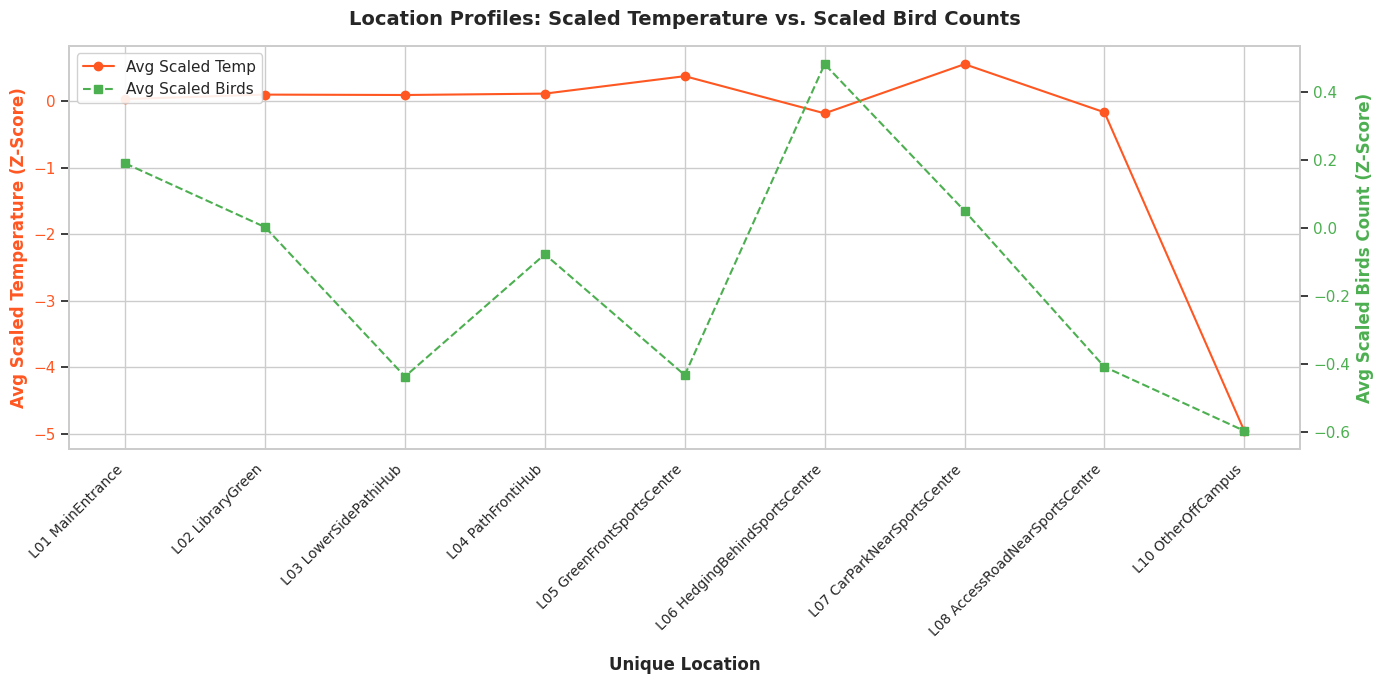

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Group by unique location and calculate the average of the scaled metrics
agg_scaled_df = df.groupby('location').agg(
    avg_temp_scaled=('temperature_c_scaled', 'mean'),
    avg_birds_scaled=('birds_count_scaled', 'mean')
).reset_index()

# Sort locations alphabetically
agg_scaled_df = agg_scaled_df.sort_values(by='location').reset_index(drop=True)

# Set the styling theme
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(14, 7))

# Line 1: Average Scaled Temperature (Left Y-axis)
color1 = '#FF5722'
ax1.set_xlabel('Unique Location', fontweight='bold', labelpad=12)
ax1.set_ylabel('Avg Scaled Temperature (Z-Score)', color=color1, fontweight='bold')
line1 = ax1.plot(agg_scaled_df['location'], agg_scaled_df['avg_temp_scaled'], color=color1, marker='o', linewidth=1.5, label='Avg Scaled Temp')
ax1.tick_params(axis='y', labelcolor=color1)

# Line 2: Average Scaled Birds Count (Right Y-axis)
ax2 = ax1.twinx()
color2 = '#4CAF50'
ax2.set_ylabel('Avg Scaled Birds Count (Z-Score)', color=color2, fontweight='bold')
line2 = ax2.plot(agg_scaled_df['location'], agg_scaled_df['avg_birds_scaled'], color=color2, marker='s', linewidth=1.5, linestyle='--', label='Avg Scaled Birds')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.grid(False) # Prevent overlapping gridlines

# Configure X-axis to display exactly one label per unique location
ax1.set_xticks(range(len(agg_scaled_df)))
ax1.set_xticklabels(agg_scaled_df['location'], rotation=45, ha='right', fontsize=10)

# Combine legends from both axes
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.title('Location Profiles: Scaled Temperature vs. Scaled Bird Counts', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

The above code creates a scatter plot that shows the relationship between bird count by location, and the average tempature in C. Note that the temperature and bird count values have been scaled. Also, the tempature at the HedgingBehindSportsCentre has the most bird count, likely due to there being shelter and the addition of hedging.

# K-Means Clustering

The below code preforms K-Means Clustering using the 4 scaled features made previously, since there are 4 values

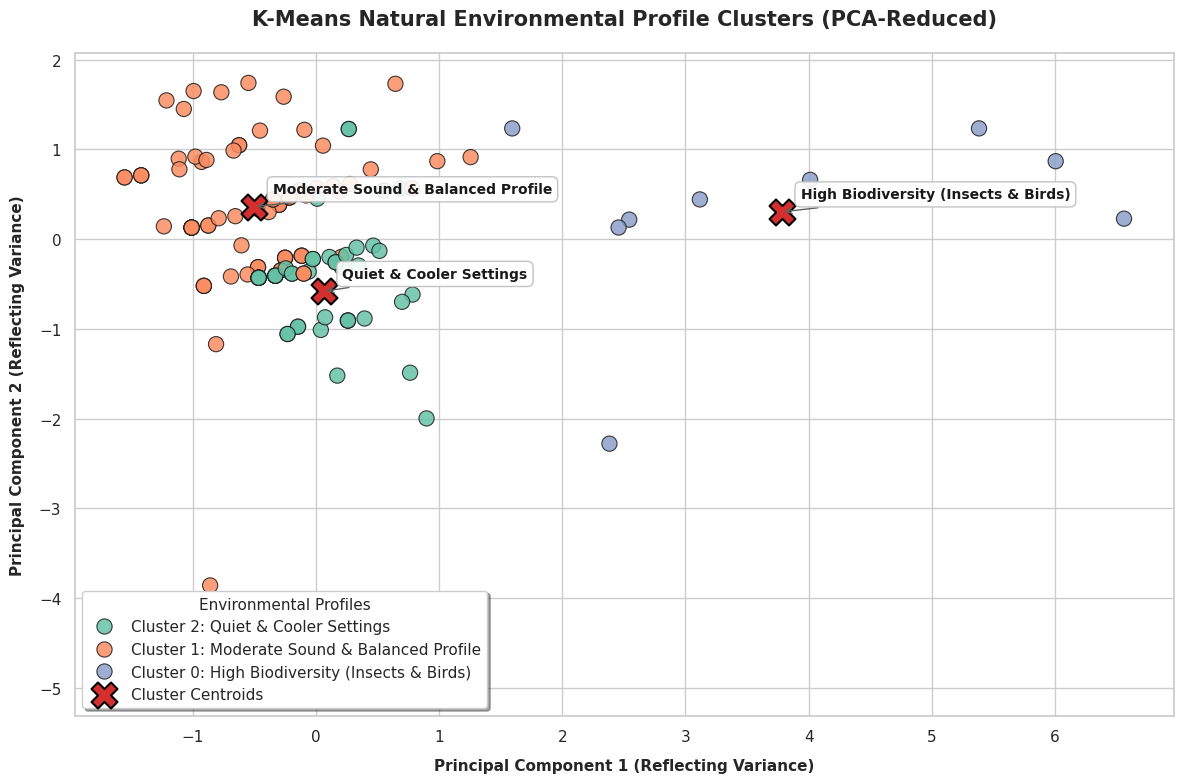

In [85]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 1. Define and extract the four scaled features
features = [
    'insects_count_scaled',
    'birds_count_scaled',
    'temperature_c_scaled',
    'sound_level_scaled'
]
X = df[features]

# 2. Fit K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['kmeans_cluster'] = kmeans.fit_predict(X)

# 3. Project 4D data to 2D using PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
df['pca_1'] = X_pca[:, 0]
df['pca_2'] = X_pca[:, 1]

# Define friendly descriptive labels for the clusters based on their centroids
cluster_profiles = {
    0: "Cluster 0: High Biodiversity (Insects & Birds)",
    1: "Cluster 1: Moderate Sound & Balanced Profile",
    2: "Cluster 2: Quiet & Cooler Settings"
}
df['cluster_profile'] = df['kmeans_cluster'].map(cluster_profiles)

# 4. Create the stylized visualization
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8), dpi=100)

# Plot the data points grouped by their cluster profile
sns.scatterplot(
    data=df,
    x='pca_1',
    y='pca_2',
    hue='cluster_profile',
    palette='Set2',
    s=120,
    alpha=0.85,
    edgecolor='k',
    linewidth=0.8
)

# 5. Extract and map centroids to PCA space
centroids = kmeans.cluster_centers_
centroids_df = pd.DataFrame(centroids, columns=features)
centroids_pca = pca.transform(centroids_df)

# Plot the centroids as prominent markers
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    color='#D32F2F',  # Deep red
    marker='X',
    s=350,
    label='Cluster Centroids',
    edgecolor='black',
    linewidth=1.5,
    zorder=10
)

# Add clean background-shaded labels for the centroids (without unsupported shadow parameter)
for i, (cx, cy) in enumerate(centroids_pca):
    short_label = cluster_profiles[i].split(': ')[1]
    plt.annotate(
        short_label,
        xy=(cx, cy),
        xytext=(cx + 0.15, cy + 0.15),
        fontsize=10,
        fontweight='bold',
        color='#1A1A1A',
        bbox=dict(
            boxstyle='round,pad=0.4',
            facecolor='#FFFFFF',
            edgecolor='#BDBDBD',
            alpha=0.9
        ),
        arrowprops=dict(
            arrowstyle="->",
            color='#616161',
            lw=1
        ),
        zorder=11
    )

# Set labels and title with clean typography
plt.title('K-Means Natural Environmental Profile Clusters (PCA-Reduced)', fontsize=15, fontweight='bold', pad=20)
plt.xlabel('Principal Component 1 (Reflecting Variance)', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Principal Component 2 (Reflecting Variance)', fontsize=11, fontweight='bold', labelpad=10)

# Style and position the legend
plt.legend(
    title='Environmental Profiles',
    title_fontsize='11',
    loc='lower left',
    frameon=True,
    shadow=True,
    facecolor='white'
)

plt.tight_layout()
plt.show()

In the above K-Means clustering graph, the relationship between trends in this specific circumstance can be seen.

The first principal component seperates samples horizontally. It is heavily influenced by factors that separate quiet, lower-biodiversity spots from lively, biodiverse spots (e.g., bird and insect counts). It clearly isolates High Biodiversity from Clusters that have Cooler and Moderate Sound/Profile.

The second principal component seperates the samples vertically, It differentiates the 'Moderate and Balanced' data from data that was added to the 'Quiet and Cooler' cluster. This axis shows differences in data such as temperature and sound levels, in places that had High Biodiveristy.

# Further Analysis

Using labled clusters, a row number could be assigned to each cluster to help identify each clusters data, this could help to identify the actual, unscaled average values, for things like temperature, noise, etc.

## Decision Logs:


A new column of tempature_c_clean has been added, this shows the values gotten in tempature in a cleaner more consistant way.

Added a K-Means Plot


## Week 6: 15/10/2026

Code was added which cleaned up the missing data from all the rows of the excel sheet, then the table was edited to show the data in a way that is easier to read.

## Week 7: 22/10/2026

This week, code was added that further cleaned the tempature values, then scaling was used for the numerical values, and a line chart of the birds by location versus tempature was created.

## Week 8: 05/11/2026
This week, I changed the display code for the scatter plot to show every location in a more satisfying layout, added headers to table of contents along with a scaled table and improvements to the bode plot.

## Week 9: 12/11/2026

During this lab, I added a k-means cluster which took 4 values, and ouputted them onto a k-means cluster plot, I also fixed small errors in code, and reordered some of the graphs and code so it makes sense logically


## Reflection

By the end of the 7th week, I was able to output a 4 value K-Means cluster plot, and a scatter plot, using data that I imported and cleaned over various Labs.

I wanted to somehow compare and plot the relationship between the temperature and noise of a location, with the insect and bird count of the same location. To do this, data was to be imported and then cleaned, to fix errors or inconsistencies made after import.

Empty, or 'trailing', rows and columns were the first to be removed, to avoid adding any unnecessary data that wasnt needed. Once that was done, a table was printed to give a visualisation on the cleaned data that was now left. In my situation, 5 empty rows and columns were cleaned and removed from the table data. Also, some temperature values had been assigned the symbol °C. This was also cleaned.

Next, the values which I wanted for my particular project had to be encoded and scaled. Sound level, Insects, Birds and Temperature values all had to be scaled or encoded. This was done to further clean any inconsistencies. In my code, Sound level is displayed as categorical data, specifically ordinal categorical data. Where the order went from: Quiet < Moderate < Loud. If the sound mapping is not added, the value cannont be read, as the machine cannot preform a mathmatical operation on a string, so theyre mapped to numbers 0-2. The code scaled the three different sound levels into three encoded values 0, 1, and 3. Once these are scaled using standard deviation, they can be easier to read and interpret. All numerical data had been given a standard deviation of 1 and a mean of 0

Once data was scaled and encoded, it was able to be plotted. I used a scatter plot to see the relationship between scaled temperature and scaled bird count, on a scatter plot. Using my displayed data, my understanding is that the HedgingBehindSportsCentre has the highest bird count (Z-score of ~0.48). Meanwhile, the orange line shows that this location has a slightly below-average temperature, likey due to the dense vegetation providing shelter.

On the K-Means Clustering Plot, this graph showed the link between biodiveristy and noise on the campus. Cluster 0 (Insects & Birds) are located on the quieter, cooler side of the spectrum, which is the right. And Clusters 1 and 2, places which had moderate sound and cooler temperature, were on the left.

## Limitations

The limitations during this project were mainly time limitations. There was a lot of data to clean and code, and anything could have been compaired/contrased. If I had more time, I would have further analysed the K-Means Cluster to label each, for better identification of where data is coming from.